### Mount Google Drive
Run the cell below to authorize Colab to access your Google Drive files.

Batch-00 treatment on `v2_session_phase/window_15s_step_5s/good_only.csv`. Models, feature lists, hyperparameters, split schemes, rolling features, balancing, and novelty detection follow the original notebook. Dataset labels are read directly from the v2 CSV.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Load the CSV File
This notebook uses the dataset path below. Upload the corresponding v2 folder to Drive before running the notebook.


In [2]:
import pandas as pd

file_path = '/content/drive/MyDrive/Penelitian-Adaptive-IDE/Dataset/v2_session_phase/window_15s_step_5s/good_only.csv'

df = None
try:
    df = pd.read_csv(file_path)
except FileNotFoundError as error:
    raise FileNotFoundError(
        f"CSV not found: {file_path}. Upload the matching v2 dataset folder to Drive."
    ) from error

print(f"Loaded {len(df)} rows from: {file_path}")
display(df.head())


Loaded 811 rows from: /content/drive/MyDrive/Penelitian-Adaptive-IDE/Dataset/v2_session_phase/window_15s_step_5s/good_only.csv


,window_id,participant_id,session_id,session_folder,team_review_group,participant_note,repeated_task,window_start,window_end,window_seconds,...,head_yaw_std,gaze_x_norm_mean,gaze_x_norm_std,gaze_y_norm_mean,gaze_y_norm_std,eye_state_fixation_ratio,eye_state_saccade_ratio,eye_state_transition_ratio,eye_state_unclassified_ratio,eye_state_other_ratio
0,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:15:44.532408+07:00,2026-10-30T10:15:59.532408+07:00,15,...,6.075876,0.361108,0.148448,0.446633,0.265356,0.201087,0.255435,0.130435,0.413043,0.0
1,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:15:49.532408+07:00,2026-10-30T10:16:04.532408+07:00,15,...,2.411120,0.302864,0.103625,0.414827,0.213252,0.212534,0.231608,0.182561,0.373297,0.0
2,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:15:54.532408+07:00,2026-10-30T10:16:09.532408+07:00,15,...,1.331606,0.342515,0.111582,0.455483,0.137915,0.274627,0.217910,0.194030,0.313433,0.0
3,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:14.532408+07:00,2026-10-30T10:16:29.532408+07:00,15,...,1.030111,0.360550,0.092666,0.595034,0.258323,0.336957,0.144022,0.274457,0.244565,0.0
4,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:19.532408+07:00,2026-10-30T10:16:34.532408+07:00,15,...,1.552441,0.379578,0.107110,0.567920,0.249483,0.296610,0.220339,0.189266,0.293785,0.0


In [3]:
df_active = df.copy(deep=True)
print(f"Created a clone of the DataFrame with {len(df_active)} rows.")

Created a clone of the DataFrame with 811 rows.


### Validate the Dataset Labels
Use the existing `cognitive_load_label` column. Difficulty and phase remain metadata; they are not used to recreate the v2 target.


In [4]:
if 'cognitive_load_label' not in df_active.columns:
    raise ValueError("The v2 CSV must contain cognitive_load_label. Do not recreate it from difficulty_level.")

valid_labels = df_active['cognitive_load_label'].isin(['Low', 'Medium', 'High'])
if not valid_labels.all():
    invalid_labels = df_active.loc[~valid_labels, 'cognitive_load_label'].unique().tolist()
    raise ValueError(f"Missing or invalid cognitive_load_label values: {invalid_labels}")

display(df_active.head())


,window_id,participant_id,session_id,session_folder,team_review_group,participant_note,repeated_task,window_start,window_end,window_seconds,...,head_yaw_std,gaze_x_norm_mean,gaze_x_norm_std,gaze_y_norm_mean,gaze_y_norm_std,eye_state_fixation_ratio,eye_state_saccade_ratio,eye_state_transition_ratio,eye_state_unclassified_ratio,eye_state_other_ratio
0,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:15:44.532408+07:00,2026-10-30T10:15:59.532408+07:00,15,...,6.075876,0.361108,0.148448,0.446633,0.265356,0.201087,0.255435,0.130435,0.413043,0.0
1,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:15:49.532408+07:00,2026-10-30T10:16:04.532408+07:00,15,...,2.411120,0.302864,0.103625,0.414827,0.213252,0.212534,0.231608,0.182561,0.373297,0.0
2,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:15:54.532408+07:00,2026-10-30T10:16:09.532408+07:00,15,...,1.331606,0.342515,0.111582,0.455483,0.137915,0.274627,0.217910,0.194030,0.313433,0.0
3,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:14.532408+07:00,2026-10-30T10:16:29.532408+07:00,15,...,1.030111,0.360550,0.092666,0.595034,0.258323,0.336957,0.144022,0.274457,0.244565,0.0
4,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:19.532408+07:00,2026-10-30T10:16:34.532408+07:00,15,...,1.552441,0.379578,0.107110,0.567920,0.249483,0.296610,0.220339,0.189266,0.293785,0.0


In [5]:
feature_df = df_active.copy(deep=True)
display(feature_df.head(10))

,window_id,participant_id,session_id,session_folder,team_review_group,participant_note,repeated_task,window_start,window_end,window_seconds,...,head_yaw_std,gaze_x_norm_mean,gaze_x_norm_std,gaze_y_norm_mean,gaze_y_norm_std,eye_state_fixation_ratio,eye_state_saccade_ratio,eye_state_transition_ratio,eye_state_unclassified_ratio,eye_state_other_ratio
0,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:15:44.532408+07:00,2026-10-30T10:15:59.532408+07:00,15,...,6.075876,0.361108,0.148448,0.446633,0.265356,0.201087,0.255435,0.130435,0.413043,0.0
1,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:15:49.532408+07:00,2026-10-30T10:16:04.532408+07:00,15,...,2.411120,0.302864,0.103625,0.414827,0.213252,0.212534,0.231608,0.182561,0.373297,0.0
2,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:15:54.532408+07:00,2026-10-30T10:16:09.532408+07:00,15,...,1.331606,0.342515,0.111582,0.455483,0.137915,0.274627,0.217910,0.194030,0.313433,0.0
3,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:14.532408+07:00,2026-10-30T10:16:29.532408+07:00,15,...,1.030111,0.360550,0.092666,0.595034,0.258323,0.336957,0.144022,0.274457,0.244565,0.0
4,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:19.532408+07:00,2026-10-30T10:16:34.532408+07:00,15,...,1.552441,0.379578,0.107110,0.567920,0.249483,0.296610,0.220339,0.189266,0.293785,0.0
5,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:24.532408+07:00,2026-10-30T10:16:39.532408+07:00,15,...,2.531849,0.354823,0.120097,0.439988,0.261610,0.275362,0.269565,0.130435,0.324638,0.0
6,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:29.532408+07:00,2026-10-30T10:16:44.532408+07:00,15,...,2.562913,0.339957,0.121676,0.370561,0.245368,0.211656,0.276074,0.168712,0.343558,0.0
7,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:34.532408+07:00,2026-10-30T10:16:49.532408+07:00,15,...,2.684328,0.310983,0.105675,0.307334,0.198682,0.304985,0.202346,0.181818,0.310850,0.0
8,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:39.532408+07:00,2026-10-30T10:16:54.532408+07:00,15,...,1.654125,0.342169,0.104429,0.335318,0.157761,0.341463,0.151762,0.265583,0.241192,0.0
9,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,Andrean,proposed_good,NaN,False,2026-10-30T10:16:44.532408+07:00,2026-10-30T10:16:59.532408+07:00,15,...,2.020557,0.343610,0.079207,0.385989,0.157774,0.372840,0.111111,0.318519,0.197531,0.0


In [6]:
len(feature_df)

811

In [7]:
from importlib.util import find_spec
from importlib.metadata import version
import subprocess
import sys

packages = {'sklearn': 'scikit-learn>=1.2', 'xgboost': 'xgboost', 'imblearn': 'imbalanced-learn'}
missing_packages = [package for module, package in packages.items() if find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing_packages])

print({package: version(package) for package in ['scikit-learn', 'xgboost', 'imbalanced-learn']})


{'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'imbalanced-learn': '0.14.2'}


Distribution of Cognitive Load Labels:


,count
cognitive_load_label,
High,338
Medium,271
Low,202


/tmp/ipykernel_9008/1153145322.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=feature_df, x='cognitive_load_label', order=['Low', 'Medium', 'High'], palette='viridis')


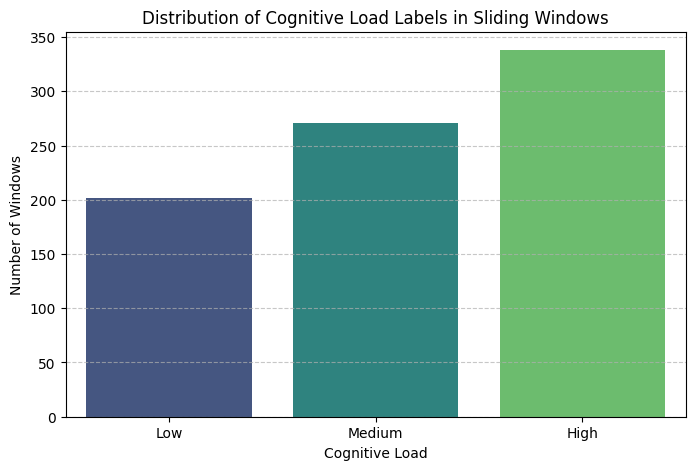

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate and display the exact counts (including any NaN values)
label_counts = feature_df['cognitive_load_label'].value_counts(dropna=False)
print("Distribution of Cognitive Load Labels:")
display(label_counts)

# Visualize the distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=feature_df, x='cognitive_load_label', order=['Low', 'Medium', 'High'], palette='viridis')
plt.title('Distribution of Cognitive Load Labels in Sliding Windows')
plt.xlabel('Cognitive Load')
plt.ylabel('Number of Windows')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


# ML Model

In [9]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import accuracy_score, classification_report
from sklearn.impute import SimpleImputer

# 1. Verify and clean the target label
# (Assuming your dataframe has a column named 'cognitive_load_label')
if 'cognitive_load_label' not in feature_df.columns:
    raise ValueError("The 'cognitive_load_label' column is missing from feature_df!")

df_clean = feature_df.dropna(subset=['cognitive_load_label']).copy()

# 2. Select the optimal predictive features
# We exclude metadata (window_id), coverage metrics, and validation scores,
# focusing purely on the physiological and behavioral biometrics.
feature_cols = [
    # HRV Features
    'rmssd_ms', 'sdnn_ms', 'rmssd_baseline_ratio',

    # Blink & Eye Aspect Ratio
    'blink_rate_per_minute', 'ear_left_mean', 'ear_right_mean',
    'ear_left_std', 'ear_right_std',

    # Iris / Pupillometry
    'iris_size_estimate_mean', 'iris_size_estimate_std',
    'iris_size_delta_std', # Acts as pupil volatility

    # Head Pose (Correlates with leaning in during high difficulty)
    'head_pitch_mean', 'head_yaw_mean', 'head_pitch_std', 'head_yaw_std',

    # Gaze Dispersion (Standard deviation represents how widely they are scanning)
    'gaze_x_norm_std', 'gaze_y_norm_std',

    # Eye States (Behavioral Reading Patterns)
    'eye_state_fixation_ratio', 'eye_state_saccade_ratio'
]

X = df_clean[feature_cols].values
y = df_clean['cognitive_load_label'].values

# 3. Handle NaNs (Scikit-Learn Random Forest cannot natively handle NaNs)
# We use a median imputer so missing HRV or Eye Data doesn't crash the model
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
X_imputed = imputer.fit_transform(X)

# 4. Initialize TimeSeriesSplit and the Model
tscv = TimeSeriesSplit(n_splits=5)
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    class_weight='balanced_subsample', # Handles class imbalance
    random_state=42
)

fold = 1
accuracies = []

print("Training Random Forest on Advanced Features with Time Series Split...\n")

# 5. Train and Evaluate chronologically
for train_index, test_index in tscv.split(X_imputed):
    X_train, X_test = X_imputed[train_index], X_imputed[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Train the model on past windows
    rf_model.fit(X_train, y_train)

    # Test the model on future windows
    predictions = rf_model.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    accuracies.append(acc)

    print(f"Fold {fold} | Train Size: {len(X_train)}, Test Size: {len(X_test)} | Accuracy: {acc:.2f}")
    fold += 1

print(f"\nAverage Accuracy: {np.mean(accuracies):.2f}")

# 6. Detailed Breakdown from the Final Fold
print("\nFinal Fold Classification Report:")
print(classification_report(y_test, predictions, zero_division=0))

# 7. Extract Feature Importance
print("\nFeature Importances:")
importances = rf_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(importance_df.to_string(index=False))


Training Random Forest on Advanced Features with Time Series Split...

Fold 1 | Train Size: 136, Test Size: 135 | Accuracy: 0.02
Fold 2 | Train Size: 271, Test Size: 135 | Accuracy: 0.30
Fold 3 | Train Size: 406, Test Size: 135 | Accuracy: 0.03
Fold 4 | Train Size: 541, Test Size: 135 | Accuracy: 0.27
Fold 5 | Train Size: 676, Test Size: 135 | Accuracy: 0.28

Average Accuracy: 0.18

Final Fold Classification Report:
              precision    recall  f1-score   support

        High       0.65      0.20      0.31        64
         Low       0.22      0.88      0.35        26
      Medium       0.20      0.04      0.07        45

    accuracy                           0.28       135
   macro avg       0.36      0.38      0.24       135
weighted avg       0.42      0.28      0.24       135


Feature Importances:
                 Feature  Importance
         head_pitch_mean    0.153060
 iris_size_estimate_mean    0.098833
    rmssd_baseline_ratio    0.098217
eye_state_fixation_ratio    0

Compare Result

# XGBoost Model

In [10]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import accuracy_score, classification_report

# 1. Clean the target label and map to numeric classes for XGBoost
if 'cognitive_load_label' not in feature_df.columns:
    raise ValueError("The 'cognitive_load_label' column is missing from feature_df!")

df_clean = feature_df.dropna(subset=['cognitive_load_label']).copy()

label_map = {'Low': 0, 'Medium': 1, 'High': 2}
reverse_label_map = {0: 'Low', 1: 'Medium', 2: 'High'}
df_clean['encoded_label'] = df_clean['cognitive_load_label'].map(label_map)

# 2. Select the optimal predictive features
feature_cols = [
    # HRV Features
    'rmssd_ms', 'sdnn_ms', 'rmssd_baseline_ratio',

    # Blink & Eye Aspect Ratio
    'blink_rate_per_minute', 'ear_left_mean', 'ear_right_mean',
    'ear_left_std', 'ear_right_std',

    # Iris / Pupillometry
    'iris_size_estimate_mean', 'iris_size_estimate_std',
    'iris_size_delta_std',

    # Head Pose
    'head_pitch_mean', 'head_yaw_mean', 'head_pitch_std', 'head_yaw_std',

    # Gaze Dispersion
    'gaze_x_norm_std', 'gaze_y_norm_std',

    # Eye States
    'eye_state_fixation_ratio', 'eye_state_saccade_ratio'
]

# Extract feature matrix and target vector directly (no imputation)
X = df_clean[feature_cols].values
y = df_clean['encoded_label'].values

# 3. Initialize TimeSeriesSplit and XGBClassifier
tscv = TimeSeriesSplit(n_splits=5)

xgb_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=3,
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    missing=np.nan,            # Crucial: Tells XGBoost how to handle missing data
    random_state=42,
    eval_metric='mlogloss'
)

fold = 1
accuracies = []

print("Training XGBoost on Advanced Features (Native NaN Handling)...\n")

# 4. Train and Evaluate chronologically
for train_index, test_index in tscv.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Fit the model; XGBoost routes NaNs automatically
    xgb_model.fit(X_train, y_train)

    # Predict on unseen future windows
    predictions_encoded = xgb_model.predict(X_test)
    acc = accuracy_score(y_test, predictions_encoded)
    accuracies.append(acc)

    print(f"Fold {fold} | Train Size: {len(X_train)}, Test Size: {len(X_test)} | Accuracy: {acc:.2f}")
    fold += 1

print(f"\nAverage Accuracy: {np.mean(accuracies):.2f}")

# 5. Map predictions back to strings for the final classification report
final_y_test_strings = [reverse_label_map[val] for val in y_test]
final_predictions_strings = [reverse_label_map[val] for val in predictions_encoded]

print("\nFinal Fold Classification Report:")
print(classification_report(final_y_test_strings, final_predictions_strings,
                            labels=['Low', 'Medium', 'High'], zero_division=0))

# 6. Extract Feature Importance
print("\nFeature Importances (Gain):")
importances = xgb_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(importance_df.to_string(index=False))

Training XGBoost on Advanced Features (Native NaN Handling)...

Fold 1 | Train Size: 136, Test Size: 135 | Accuracy: 0.04
Fold 2 | Train Size: 271, Test Size: 135 | Accuracy: 0.39
Fold 3 | Train Size: 406, Test Size: 135 | Accuracy: 0.03
Fold 4 | Train Size: 541, Test Size: 135 | Accuracy: 0.26
Fold 5 | Train Size: 676, Test Size: 135 | Accuracy: 0.30

Average Accuracy: 0.21

Final Fold Classification Report:
              precision    recall  f1-score   support

         Low       0.20      0.69      0.31        26
      Medium       0.00      0.00      0.00        45
        High       0.52      0.36      0.43        64

    accuracy                           0.30       135
   macro avg       0.24      0.35      0.24       135
weighted avg       0.29      0.30      0.26       135


Feature Importances (Gain):
                 Feature  Importance
    rmssd_baseline_ratio    0.114955
           ear_left_mean    0.087067
         head_pitch_mean    0.076511
          head_pitch_std    0

New XGBoost

In [11]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_sample_weight

# 1. Clean and Encode Labels
if 'cognitive_load_label' not in feature_df.columns:
    raise ValueError("The 'cognitive_load_label' column is missing from feature_df!")

df_clean = feature_df.dropna(subset=['cognitive_load_label']).copy()
label_map = {'Low': 0, 'Medium': 1, 'High': 2}
reverse_label_map = {0: 'Low', 1: 'Medium', 2: 'High'}
df_clean['encoded_label'] = df_clean['cognitive_load_label'].map(label_map)

# 2. Parse ISO Timestamps and Create Time Blocks
# Convert the ISO timestamp string to standard epoch seconds
timestamp_seconds = (
    pd.to_datetime(df_clean['window_start'], utc=True) - pd.Timestamp('1970-01-01', tz='UTC')
).dt.total_seconds()

# Normalize it so the recording session starts exactly at 0.0 seconds
normalized_seconds = timestamp_seconds - timestamp_seconds.min()

# Group into 120-second (2-minute) chunks to prevent data leakage in sliding windows
df_clean['time_block_id'] = (normalized_seconds // 120).astype(int)

# 3. Define Features, Target, and Groups
feature_cols = [
    # HRV Features
    'rmssd_ms', 'sdnn_ms', 'rmssd_baseline_ratio',
    # Blink & Eye Aspect Ratio
    'blink_rate_per_minute', 'ear_left_mean', 'ear_right_mean',
    'iris_size_estimate_std', 'iris_size_delta_std',
    # Head Pose
    'head_pitch_std', 'head_yaw_std',
    # Gaze & Eye States
    'gaze_x_norm_std', 'gaze_y_norm_std',
    'eye_state_fixation_ratio', 'eye_state_saccade_ratio'
]

X = df_clean[feature_cols].values
y = df_clean['encoded_label'].values
groups = df_clean['time_block_id'].values

# 4. Initialize GroupKFold and XGBoost
gkf = GroupKFold(n_splits=5)

xgb_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=3,
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    missing=np.nan, # Native handling for missing sensor data
    random_state=42
)

fold = 1
accuracies = []
all_y_true = []
all_y_pred = []

print("Training XGBoost with Blocked Validation and Sample Weights...\n")

# 5. Train and Evaluate
for train_index, test_index in gkf.split(X, y, groups=groups):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Calculate sample weights dynamically for the current fold to combat class imbalance
    weights = compute_sample_weight(class_weight='balanced', y=y_train)

    # Fit the model using the calculated weights
    xgb_model.fit(X_train, y_train, sample_weight=weights)

    # Predict on the unseen time blocks
    predictions = xgb_model.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    accuracies.append(acc)

    # Store predictions for the aggregate classification report
    all_y_true.extend(y_test)
    all_y_pred.extend(predictions)

    print(f"Fold {fold} | Accuracy: {acc:.2f}")
    fold += 1

print(f"\nAverage Blocked Accuracy: {np.mean(accuracies):.2f}")

# 6. Aggregate Classification Report
final_y_test_strings = [reverse_label_map[val] for val in all_y_true]
final_predictions_strings = [reverse_label_map[val] for val in all_y_pred]

print("\nAggregate Classification Report (All Folds Combined):")
print(classification_report(final_y_test_strings, final_predictions_strings,
                            labels=['Low', 'Medium', 'High'], zero_division=0))

# 7. Overall Feature Importance (from the final fold's tree)
print("\nFeature Importances (Gain) from Final Fold:")
importances = xgb_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(importance_df.to_string(index=False))


Training XGBoost with Blocked Validation and Sample Weights...

Fold 1 | Accuracy: 0.40
Fold 2 | Accuracy: 0.60
Fold 3 | Accuracy: 0.42
Fold 4 | Accuracy: 0.54
Fold 5 | Accuracy: 0.48

Average Blocked Accuracy: 0.49

Aggregate Classification Report (All Folds Combined):
              precision    recall  f1-score   support

         Low       0.38      0.32      0.35       202
      Medium       0.41      0.48      0.44       271
        High       0.62      0.60      0.61       338

    accuracy                           0.49       811
   macro avg       0.47      0.47      0.47       811
weighted avg       0.49      0.49      0.49       811


Feature Importances (Gain) from Final Fold:
                 Feature  Importance
    rmssd_baseline_ratio    0.118893
           ear_left_mean    0.099001
                rmssd_ms    0.084318
                 sdnn_ms    0.080290
            head_yaw_std    0.079694
eye_state_fixation_ratio    0.078721
   blink_rate_per_minute    0.075301
  iris_

New RandomForest incorporating time-blocked validation, rolling memory features, collinear pruning, and safe data imputation

In [12]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, classification_report
from sklearn.impute import SimpleImputer

# 1. Clean Labels and Parse Timestamps
df_clean = feature_df.dropna(subset=['cognitive_load_label']).copy()
df_clean['encoded_label'] = df_clean['cognitive_load_label'].map({'Low': 0, 'Medium': 1, 'High': 2})
reverse_label_map = {0: 'Low', 1: 'Medium', 2: 'High'}

timestamp_seconds = (
    pd.to_datetime(df_clean['window_start'], utc=True) - pd.Timestamp('1970-01-01', tz='UTC')
).dt.total_seconds()
normalized_seconds = timestamp_seconds - timestamp_seconds.min()
df_clean['time_block_id'] = (normalized_seconds // 120).astype(int)

# 2. Prune Collinear Features and Add Temporal Memory
# Combine symmetric eye features
df_clean['ear_mean'] = df_clean[['ear_left_mean', 'ear_right_mean']].mean(axis=1)
df_clean['ear_std'] = df_clean[['ear_left_std', 'ear_right_std']].mean(axis=1)

# Sort chronologically to safely calculate rolling features
df_clean = df_clean.sort_values(by='window_start').reset_index(drop=True)

# Add 3-window rolling memory
df_clean['rmssd_rolling_mean_3'] = df_clean['rmssd_ms'].rolling(window=3, min_periods=1).mean()
df_clean['pupil_volatility_rolling_3'] = df_clean['iris_size_delta_std'].rolling(window=3, min_periods=1).mean()
df_clean['rmssd_trend'] = df_clean['rmssd_ms'].diff().fillna(0)

# 3. Define Features, Target, and Groups
feature_cols = [
    'rmssd_ms', 'rmssd_rolling_mean_3', 'rmssd_trend', 'sdnn_ms', 'rmssd_baseline_ratio',
    'blink_rate_per_minute', 'ear_mean', 'ear_std',
    'iris_size_estimate_std', 'iris_size_delta_std', 'pupil_volatility_rolling_3',
    'head_pitch_std', 'head_yaw_std', 'gaze_x_norm_std', 'gaze_y_norm_std',
    'eye_state_fixation_ratio', 'eye_state_saccade_ratio'
]

X = df_clean[feature_cols].values
y = df_clean['encoded_label'].values
groups = df_clean['time_block_id'].values

# 4. Initialize GroupKFold, Imputer, and Random Forest
gkf = GroupKFold(n_splits=5)
imputer = SimpleImputer(strategy='median', keep_empty_features=True)

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    class_weight='balanced_subsample', # Random Forest handles class weights natively
    random_state=42
)

fold = 1
accuracies = []
all_y_true = []
all_y_pred = []

print("Training Advanced Random Forest with Blocked Validation...\n")

# 5. Train and Evaluate inside the loop to prevent data leakage
for train_index, test_index in gkf.split(X, y, groups=groups):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Fit imputer ONLY on the training data, then transform both
    X_train_imputed = imputer.fit_transform(X_train)
    X_test_imputed = imputer.transform(X_test)

    # Train the Random Forest
    rf_model.fit(X_train_imputed, y_train)

    # Predict
    predictions = rf_model.predict(X_test_imputed)
    acc = accuracy_score(y_test, predictions)
    accuracies.append(acc)

    all_y_true.extend(y_test)
    all_y_pred.extend(predictions)

    print(f"Fold {fold} | Accuracy: {acc:.2f}")
    fold += 1

print(f"\nAverage Blocked Accuracy: {np.mean(accuracies):.2f}")

# 6. Aggregate Classification Report
final_y_test_strings = [reverse_label_map[val] for val in all_y_true]
final_predictions_strings = [reverse_label_map[val] for val in all_y_pred]

print("\nAggregate Classification Report:")
print(classification_report(final_y_test_strings, final_predictions_strings,
                            labels=['Low', 'Medium', 'High'], zero_division=0))


Training Advanced Random Forest with Blocked Validation...

Fold 1 | Accuracy: 0.38
Fold 2 | Accuracy: 0.62
Fold 3 | Accuracy: 0.44
Fold 4 | Accuracy: 0.60
Fold 5 | Accuracy: 0.44

Average Blocked Accuracy: 0.50

Aggregate Classification Report:
              precision    recall  f1-score   support

         Low       0.37      0.29      0.32       202
      Medium       0.43      0.55      0.48       271
        High       0.64      0.58      0.61       338

    accuracy                           0.50       811
   macro avg       0.48      0.47      0.47       811
weighted avg       0.50      0.50      0.49       811



Newer XGBoost model

In [13]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_sample_weight

# 1. Clean Labels and Parse Timestamps
if 'cognitive_load_label' not in feature_df.columns:
    raise ValueError("The 'cognitive_load_label' column is missing from feature_df!")

df_clean = feature_df.dropna(subset=['cognitive_load_label']).copy()
label_map = {'Low': 0, 'Medium': 1, 'High': 2}
reverse_label_map = {0: 'Low', 1: 'Medium', 2: 'High'}
df_clean['encoded_label'] = df_clean['cognitive_load_label'].map(label_map)

# Convert ISO strings to standard epoch seconds and normalize to 0.0
timestamp_seconds = (
    pd.to_datetime(df_clean['window_start'], utc=True) - pd.Timestamp('1970-01-01', tz='UTC')
).dt.total_seconds()
df_clean['normalized_seconds'] = timestamp_seconds - timestamp_seconds.min()

# 2. Sort Chronologically (CRITICAL for rolling memory and time blocks)
df_clean = df_clean.sort_values(by='normalized_seconds').reset_index(drop=True)

# Group into 120-second (2-minute) chunks to prevent data leakage
df_clean['time_block_id'] = (df_clean['normalized_seconds'] // 120).astype(int)

# 3. Feature Pruning (Combine Left and Right Eyes)
df_clean['ear_mean'] = df_clean[['ear_left_mean', 'ear_right_mean']].mean(axis=1)
df_clean['ear_std'] = df_clean[['ear_left_std', 'ear_right_std']].mean(axis=1)

cols_to_drop = ['ear_left_mean', 'ear_right_mean', 'ear_left_std', 'ear_right_std']
df_clean = df_clean.drop(columns=cols_to_drop)

# 4. Temporal Memory (Rolling Averages and Deltas)
# Calculate a 3-window rolling average (the last ~1.5 minutes if step is 30s)
df_clean['rmssd_rolling_mean_3'] = df_clean['rmssd_ms'].rolling(window=3, min_periods=1).mean()
df_clean['pupil_volatility_rolling_3'] = df_clean['iris_size_delta_std'].rolling(window=3, min_periods=1).mean()

# Calculate the Delta (Trend): Is HRV dropping compared to the previous window?
df_clean['rmssd_trend'] = df_clean['rmssd_ms'].diff().fillna(0)

# 5. Define Features, Target, and Groups
feature_cols = [
    # HRV Features
    'rmssd_ms', 'rmssd_rolling_mean_3', 'rmssd_trend', 'sdnn_ms', 'rmssd_baseline_ratio',
    # Blink & Eye Aspect Ratio
    'blink_rate_per_minute', 'ear_mean', 'ear_std',
    # Iris & Pupillometry
    'iris_size_estimate_std', 'iris_size_delta_std', 'pupil_volatility_rolling_3',
    # Head Pose
    'head_pitch_std', 'head_yaw_std',
    # Gaze & Eye States
    'gaze_x_norm_std', 'gaze_y_norm_std',
    'eye_state_fixation_ratio', 'eye_state_saccade_ratio'
]

X = df_clean[feature_cols].values
y = df_clean['encoded_label'].values
groups = df_clean['time_block_id'].values

# 6. Initialize GroupKFold and XGBoost
gkf = GroupKFold(n_splits=5)

xgb_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=3,
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,             # Combat noise by using 80% of rows per tree
    colsample_bytree=0.8,      # Combat noise by using 80% of features per tree
    missing=np.nan,            # Native handling for missing sensor data
    random_state=42
)

fold = 1
accuracies = []
all_y_true = []
all_y_pred = []

print("Training Advanced XGBoost Pipeline with Temporal Memory...\n")

# 7. Train and Evaluate
for train_index, test_index in gkf.split(X, y, groups=groups):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Calculate sample weights dynamically to combat class imbalance
    weights = compute_sample_weight(class_weight='balanced', y=y_train)

    # Fit the model using the calculated weights
    xgb_model.fit(X_train, y_train, sample_weight=weights)

    # Predict on the unseen time blocks
    predictions = xgb_model.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    accuracies.append(acc)

    # Store predictions for the aggregate classification report
    all_y_true.extend(y_test)
    all_y_pred.extend(predictions)

    print(f"Fold {fold} | Accuracy: {acc:.2f}")
    fold += 1

print(f"\nAverage Blocked Accuracy: {np.mean(accuracies):.2f}")

# 8. Aggregate Classification Report
final_y_test_strings = [reverse_label_map[val] for val in all_y_true]
final_predictions_strings = [reverse_label_map[val] for val in all_y_pred]

print("\nAggregate Classification Report (All Folds Combined):")
print(classification_report(final_y_test_strings, final_predictions_strings,
                            labels=['Low', 'Medium', 'High'], zero_division=0))

# 9. Overall Feature Importance (from the final fold's tree)
print("\nFeature Importances (Gain) from Final Fold:")
importances = xgb_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(importance_df.to_string(index=False))


Training Advanced XGBoost Pipeline with Temporal Memory...

Fold 1 | Accuracy: 0.40
Fold 2 | Accuracy: 0.60
Fold 3 | Accuracy: 0.47
Fold 4 | Accuracy: 0.57
Fold 5 | Accuracy: 0.50

Average Blocked Accuracy: 0.51

Aggregate Classification Report (All Folds Combined):
              precision    recall  f1-score   support

         Low       0.40      0.35      0.37       202
      Medium       0.46      0.53      0.49       271
        High       0.61      0.59      0.60       338

    accuracy                           0.51       811
   macro avg       0.49      0.49      0.49       811
weighted avg       0.51      0.51      0.51       811


Feature Importances (Gain) from Final Fold:
                   Feature  Importance
      rmssd_rolling_mean_3    0.087146
                  rmssd_ms    0.066329
            head_pitch_std    0.064478
  eye_state_fixation_ratio    0.063952
                  ear_mean    0.063585
      rmssd_baseline_ratio    0.063377
                   ear_std    0.06

XGBoost with binary classes ('Medium' and 'High' only)

In [14]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_sample_weight

# 1. Clean Labels and Filter out 'Low'
if 'cognitive_load_label' not in feature_df.columns:
    raise ValueError("The 'cognitive_load_label' column is missing from feature_df!")

# Drop NaNs, then keep ONLY Medium and High
df_binary = feature_df.dropna(subset=['cognitive_load_label']).copy()
df_binary = df_binary[df_binary['cognitive_load_label'].isin(['Medium', 'High'])]

# Map to Binary Target (Medium = 0, High = 1)
label_map = {'Medium': 0, 'High': 1}
reverse_label_map = {0: 'Medium', 1: 'High'}
df_binary['encoded_label'] = df_binary['cognitive_load_label'].map(label_map)

# 2. Parse Timestamps and Sort Chronologically
timestamp_seconds = (
    pd.to_datetime(df_binary['window_start'], utc=True) - pd.Timestamp('1970-01-01', tz='UTC')
).dt.total_seconds()
df_binary['normalized_seconds'] = timestamp_seconds - timestamp_seconds.min()
df_binary = df_binary.sort_values(by='normalized_seconds').reset_index(drop=True)

# Create 120-second blocks to prevent data leakage in GroupKFold
df_binary['time_block_id'] = (df_binary['normalized_seconds'] // 120).astype(int)

# 3. Feature Pruning (Combine Left and Right Eyes)
df_binary['ear_mean'] = df_binary[['ear_left_mean', 'ear_right_mean']].mean(axis=1)
df_binary['ear_std'] = df_binary[['ear_left_std', 'ear_right_std']].mean(axis=1)

cols_to_drop = ['ear_left_mean', 'ear_right_mean', 'ear_left_std', 'ear_right_std']
df_binary = df_binary.drop(columns=cols_to_drop)

# 4. Temporal Memory (Rolling Averages and Deltas)
df_binary['rmssd_rolling_mean_3'] = df_binary['rmssd_ms'].rolling(window=3, min_periods=1).mean()
df_binary['pupil_volatility_rolling_3'] = df_binary['iris_size_delta_std'].rolling(window=3, min_periods=1).mean()
df_binary['rmssd_trend'] = df_binary['rmssd_ms'].diff().fillna(0)

# 5. Define Features, Target, and Groups
feature_cols = [
    'rmssd_ms', 'rmssd_rolling_mean_3', 'rmssd_trend', 'sdnn_ms', 'rmssd_baseline_ratio',
    'blink_rate_per_minute', 'ear_mean', 'ear_std',
    'iris_size_estimate_std', 'iris_size_delta_std', 'pupil_volatility_rolling_3',
    'head_pitch_std', 'head_yaw_std', 'gaze_x_norm_std', 'gaze_y_norm_std',
    'eye_state_fixation_ratio', 'eye_state_saccade_ratio'
]

X = df_binary[feature_cols].values
y = df_binary['encoded_label'].values
groups = df_binary['time_block_id'].values

# 6. Initialize GroupKFold and XGBoost (Binary Configuration)
gkf = GroupKFold(n_splits=5)

xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',  # CRITICAL: Switched to binary classification
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    missing=np.nan,
    eval_metric='logloss',
    random_state=42
)

fold = 1
accuracies = []
all_y_true = []
all_y_pred = []

print(f"Training Binary XGBoost on {len(df_binary)} samples (Medium vs High)...\n")

# 7. Train and Evaluate
for train_index, test_index in gkf.split(X, y, groups=groups):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Calculate sample weights (Medium is 968, High is 1077, so it's quite balanced)
    weights = compute_sample_weight(class_weight='balanced', y=y_train)

    xgb_model.fit(X_train, y_train, sample_weight=weights)

    predictions = xgb_model.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    accuracies.append(acc)

    all_y_true.extend(y_test)
    all_y_pred.extend(predictions)

    print(f"Fold {fold} | Accuracy: {acc:.2f}")
    fold += 1

print(f"\nAverage Binary Accuracy: {np.mean(accuracies):.2f}")

# 8. Aggregate Classification Report
final_y_test_strings = [reverse_label_map[val] for val in all_y_true]
final_predictions_strings = [reverse_label_map[val] for val in all_y_pred]

print("\nAggregate Classification Report (All Folds Combined):")
print(classification_report(final_y_test_strings, final_predictions_strings,
                            labels=['Medium', 'High'], zero_division=0))

# 9. Overall Feature Importance
print("\nFeature Importances (Gain) from Final Fold:")
importances = xgb_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(importance_df.to_string(index=False))


Training Binary XGBoost on 609 samples (Medium vs High)...

Fold 1 | Accuracy: 0.59
Fold 2 | Accuracy: 0.69
Fold 3 | Accuracy: 0.80
Fold 4 | Accuracy: 0.69
Fold 5 | Accuracy: 0.54

Average Binary Accuracy: 0.66

Aggregate Classification Report (All Folds Combined):
              precision    recall  f1-score   support

      Medium       0.61      0.65      0.63       271
        High       0.71      0.67      0.68       338

    accuracy                           0.66       609
   macro avg       0.66      0.66      0.66       609
weighted avg       0.66      0.66      0.66       609


Feature Importances (Gain) from Final Fold:
                   Feature  Importance
      rmssd_rolling_mean_3    0.167393
                  rmssd_ms    0.097851
                  ear_mean    0.069132
   eye_state_saccade_ratio    0.066102
              head_yaw_std    0.061138
           gaze_x_norm_std    0.060433
                   sdnn_ms    0.058718
            head_pitch_std    0.057860
           

XGBOOST with data augmentation

In [15]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, classification_report
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE

# [Assume df_clean is already prepared with rolling memory and time_block_id from previous steps]

# 1. Define Features, Target, and Groups
feature_cols = [
    'rmssd_ms', 'rmssd_rolling_mean_3', 'rmssd_trend', 'sdnn_ms', 'rmssd_baseline_ratio',
    'blink_rate_per_minute', 'ear_mean', 'ear_std',
    'iris_size_estimate_std', 'iris_size_delta_std', 'pupil_volatility_rolling_3',
    'head_pitch_std', 'head_yaw_std', 'gaze_x_norm_std', 'gaze_y_norm_std',
    'eye_state_fixation_ratio', 'eye_state_saccade_ratio'
]

X = df_clean[feature_cols].values
y = df_clean['encoded_label'].values
groups = df_clean['time_block_id'].values

# 2. Initialize GroupKFold, Imputer, SMOTE, and XGBoost
gkf = GroupKFold(n_splits=5)

# SMOTE requires complete data, so we must impute missing sensor drops
imputer = SimpleImputer(strategy='median', keep_empty_features=True)

# sampling_strategy='auto' automatically upsamples minority classes to match the majority class
smote = SMOTE(sampling_strategy='auto', random_state=42)

xgb_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=3,
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    # XGBoost no longer needs missing=np.nan because the imputer handles it before training
    random_state=42
)

fold = 1
accuracies = []
all_y_true = []
all_y_pred = []

print("Training XGBoost with SMOTE and Blocked Validation...\n")

# 3. Train and Evaluate INSIDE the loop
for train_index, test_index in gkf.split(X, y, groups=groups):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # STEP A: Impute missing data (Fit on training data ONLY to prevent leakage)
    X_train_imputed = imputer.fit_transform(X_train)
    X_test_imputed = imputer.transform(X_test)

    # STEP B: Apply SMOTE only to the training data
    X_train_smote, y_train_smote = smote.fit_resample(X_train_imputed, y_train)

    # Because SMOTE perfectly balances the classes, we no longer need compute_sample_weight

    # STEP C: Train XGBoost on the synthetically balanced data
    xgb_model.fit(X_train_smote, y_train_smote)

    # STEP D: Predict on the strictly real, unseen test data
    predictions = xgb_model.predict(X_test_imputed)
    acc = accuracy_score(y_test, predictions)
    accuracies.append(acc)

    all_y_true.extend(y_test)
    all_y_pred.extend(predictions)

    print(f"Fold {fold} | Original Train Size: {len(X_train)} | SMOTE Train Size: {len(X_train_smote)} | Accuracy: {acc:.2f}")
    fold += 1

print(f"\nAverage Blocked Accuracy: {np.mean(accuracies):.2f}")

# 4. Aggregate Classification Report
label_map = {'Low': 0, 'Medium': 1, 'High': 2}
reverse_label_map = {0: 'Low', 1: 'Medium', 2: 'High'}

final_y_test_strings = [reverse_label_map[val] for val in all_y_true]
final_predictions_strings = [reverse_label_map[val] for val in all_y_pred]

print("\nAggregate Classification Report (All Folds Combined):")
print(classification_report(final_y_test_strings, final_predictions_strings,
                            labels=['Low', 'Medium', 'High'], zero_division=0))


Training XGBoost with SMOTE and Blocked Validation...

Fold 1 | Original Train Size: 648 | SMOTE Train Size: 972 | Accuracy: 0.38
Fold 2 | Original Train Size: 649 | SMOTE Train Size: 705 | Accuracy: 0.62
Fold 3 | Original Train Size: 649 | SMOTE Train Size: 741 | Accuracy: 0.46
Fold 4 | Original Train Size: 649 | SMOTE Train Size: 789 | Accuracy: 0.56
Fold 5 | Original Train Size: 649 | SMOTE Train Size: 852 | Accuracy: 0.48

Average Blocked Accuracy: 0.50

Aggregate Classification Report (All Folds Combined):
              precision    recall  f1-score   support

         Low       0.38      0.36      0.37       202
      Medium       0.46      0.50      0.48       271
        High       0.61      0.58      0.59       338

    accuracy                           0.50       811
   macro avg       0.48      0.48      0.48       811
weighted avg       0.50      0.50      0.50       811



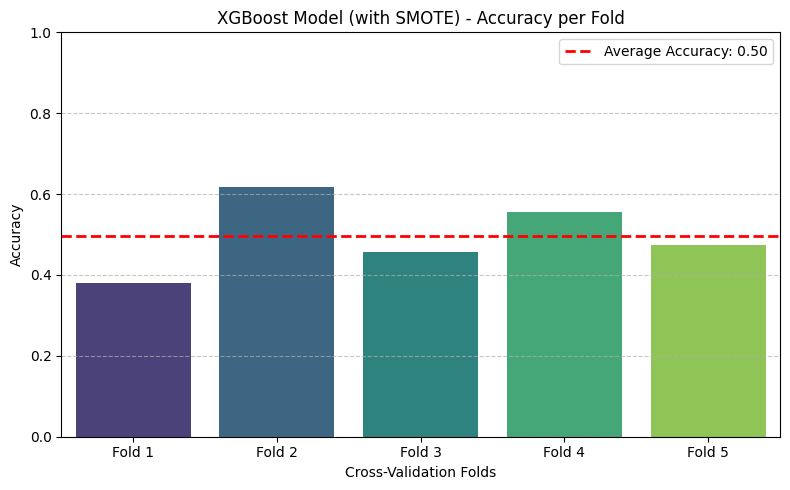

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the fold accuracies from the latest XGBoost model
plt.figure(figsize=(8, 5))
fold_numbers = [f"Fold {i+1}" for i in range(len(accuracies))]

# Create bar plot
sns.barplot(x=fold_numbers, y=accuracies, hue=fold_numbers, palette='viridis', legend=False)

# Add a horizontal line for the average accuracy
avg_acc = np.mean(accuracies)
plt.axhline(y=avg_acc, color='r', linestyle='--', linewidth=2, label=f'Average Accuracy: {avg_acc:.2f}')

plt.title('XGBoost Model (with SMOTE) - Accuracy per Fold')
plt.xlabel('Cross-Validation Folds')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)  # Set y-axis limits from 0 to 1
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Novelty detection

Median imputation is fitted on elevated training data for missing sensor values. The original 80/20 elevated split, all-Low test branch, and detector parameters are retained.


In [17]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report

# 1. Clean labels
if 'cognitive_load_label' not in feature_df.columns:
    raise ValueError("The 'cognitive_load_label' column is missing from feature_df!")

df_clean = feature_df.dropna(subset=['cognitive_load_label']).copy()

# 2. Sort Chronologically (Required for accurate rolling memory)
timestamp_seconds = (
    pd.to_datetime(df_clean['window_start'], utc=True) - pd.Timestamp('1970-01-01', tz='UTC')
).dt.total_seconds()
df_clean['normalized_seconds'] = timestamp_seconds - timestamp_seconds.min()
df_clean = df_clean.sort_values(by='normalized_seconds').reset_index(drop=True)

# 3. Generate the Missing Features (Pruning and Rolling Memory)
# Combine left and right eye metrics
df_clean['ear_mean'] = df_clean[['ear_left_mean', 'ear_right_mean']].mean(axis=1)
df_clean['ear_std'] = df_clean[['ear_left_std', 'ear_right_std']].mean(axis=1)

# Calculate temporal memory windows
df_clean['rmssd_rolling_mean_3'] = df_clean['rmssd_ms'].rolling(window=3, min_periods=1).mean()
df_clean['pupil_volatility_rolling_3'] = df_clean['iris_size_delta_std'].rolling(window=3, min_periods=1).mean()
df_clean['rmssd_trend'] = df_clean['rmssd_ms'].diff().fillna(0)

# 4. Split the data by class for Novelty Detection
# 'Elevated' (Medium/High) becomes our Normal/Inlier data
df_elevated = df_clean[df_clean['cognitive_load_label'].isin(['Medium', 'High'])].copy()

# 'Low' becomes our Anomaly/Outlier data
df_low = df_clean[df_clean['cognitive_load_label'] == 'Low'].copy()

# 5. Create chronologically safe Train and Test sets
# Use the first 80% of elevated data to map the "Normal" biometric boundary
split_idx = int(len(df_elevated) * 0.8)
train_elevated = df_elevated.iloc[:split_idx]

# The test set combines the remaining 20% unseen elevated data with ALL of the Low data
test_elevated = df_elevated.iloc[split_idx:]
test_df = pd.concat([test_elevated, df_low])

# 6. Define Features
feature_cols = [
    'rmssd_ms', 'rmssd_rolling_mean_3', 'rmssd_trend',
    'blink_rate_per_minute', 'ear_mean', 'ear_std',
    'iris_size_delta_std', 'pupil_volatility_rolling_3',
    'gaze_x_norm_std', 'gaze_y_norm_std'
]

X_train = train_elevated[feature_cols].values
X_test = test_df[feature_cols].values

# Fit missing-sensor preprocessing on elevated training rows only.
from sklearn.impute import SimpleImputer
novelty_imputer = SimpleImputer(strategy='median', keep_empty_features=True)
X_train = novelty_imputer.fit_transform(X_train)
X_test = novelty_imputer.transform(X_test)

# Map True Labels for testing:
# 1 for Inliers (Elevated), -1 for Anomalies (Low)
y_test_true = np.where(test_df['cognitive_load_label'] == 'Low', -1, 1)

# 7. Initialize and Train the Isolation Forest
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.05, # Assumes 5% of the 'Elevated' training data might be noisy outliers
    random_state=42
)

print("Training Isolation Forest on 'Elevated' data only...\n")
iso_forest.fit(X_train)

# 8. Predict and Evaluate
predictions = iso_forest.predict(X_test)

print("Novelty Detection Classification Report:")
print("  1 = Elevated Cognitive Load (Inlier)")
print(" -1 = Low Cognitive Load (Anomaly)\n")
print(classification_report(y_test_true, predictions, zero_division=0))


Training Isolation Forest on 'Elevated' data only...

Novelty Detection Classification Report:
  1 = Elevated Cognitive Load (Inlier)
 -1 = Low Cognitive Load (Anomaly)

              precision    recall  f1-score   support

          -1       0.73      0.05      0.10       202
           1       0.38      0.97      0.55       122

    accuracy                           0.40       324
   macro avg       0.56      0.51      0.32       324
weighted avg       0.60      0.40      0.27       324



New Novelty Model

In [18]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

# [Assume X_train, X_test, and y_test_true are defined exactly as before]

# 1. Feature Scaling (Crucial for spatial anomaly detection)
scaler = StandardScaler()

# Fit the scaler ONLY on the elevated training data to prevent leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. APPROACH A: Tuned Isolation Forest
# We increase contamination to 0.25 to force a much tighter boundary
iso_forest = IsolationForest(
    n_estimators=200,      # More trees for stability
    contamination=0.25,    # Shrink the boundary
    random_state=42
)

print("Training Tuned Isolation Forest...")
iso_forest.fit(X_train_scaled)
predictions_iso = iso_forest.predict(X_test_scaled)

print("\nTuned Isolation Forest Report:")
print(classification_report(y_test_true, predictions_iso, zero_division=0))

# 3. APPROACH B: One-Class SVM
# nu is similar to contamination; it determines the upper bound on training errors
# gamma='scale' automatically adjusts to the number of features
oc_svm = OneClassSVM(
    kernel='rbf',
    nu=0.25,
    gamma='scale'
)

print("\nTraining One-Class SVM...")
oc_svm.fit(X_train_scaled)
predictions_svm = oc_svm.predict(X_test_scaled)

print("\nOne-Class SVM Report:")
print(classification_report(y_test_true, predictions_svm, zero_division=0))

Training Tuned Isolation Forest...

Tuned Isolation Forest Report:
              precision    recall  f1-score   support

          -1       0.76      0.26      0.39       202
           1       0.41      0.86      0.56       122

    accuracy                           0.49       324
   macro avg       0.59      0.56      0.47       324
weighted avg       0.63      0.49      0.45       324


Training One-Class SVM...

One-Class SVM Report:
              precision    recall  f1-score   support

          -1       0.73      0.30      0.42       202
           1       0.41      0.82      0.55       122

    accuracy                           0.49       324
   macro avg       0.57      0.56      0.49       324
weighted avg       0.61      0.49      0.47       324

